# Modul Praktikum
# Community Detection pada Social Network

## A. Tujuan Praktikum
Setelah menyelesaikan praktikum ini, mahasiswa mampu:
1. membentuk graph dari data edge list;
2. memvisualisasikan struktur jaringan;
3. menjelaskan konsep community detection;
4. menerapkan algoritma Louvain, Label Propagation, dan Girvan–Newman;
5. menampilkan anggota setiap community;
6. menghitung modularity;
7. membandingkan hasil tiga algoritma;
8. menginterpretasikan perbedaan struktur community.

## C. Persiapan Library

In [1]:
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
from networkx.algorithms.community import girvan_newman

print(nx.__version__)

3.7


## D. Dataset

In [2]:
edges = [
    ("U09","U19"),
    ("U14","U15"),
    ("U13","U12"),
    ("U19","U13"),
    ("U20","U18"),
    ("U14","U06"),
    ("U16","U15"),
    ("U20","U13"),
    ("U01","U09"),
    ("U18","U12"),
    ("U02","U05"),
    ("U07","U06"),
    ("U17","U05"),
    ("U17","U18"),
    ("U11","U05"),
    ("U08","U16"),
    ("U06","U04"),
    ("U05","U19"),
    ("U08","U07"),
    ("U15","U04"),
    ("U13","U18"),
    ("U03","U18"),
    ("U04","U01"),
    ("U03","U10"),
    ("U03","U12"),
    ("U02","U19"),
    ("U01","U02"),
    ("U13","U03"),
    ("U01","U05"),
    ("U08","U15"),
    ("U06","U11"),
    ("U02","U09"),
    ("U07","U15"),
    ("U16","U06"),
    ("U09","U20"),
    ("U05","U09"),
    ("U11","U02"),
    ("U17","U13"),
    ("U18","U10"),
    ("U15","U06"),
    ("U11","U01"),
    ("U14","U01"),
    ("U07","U16"),
    ("U12","U10"),
    ("U16","U04"),
    ("U20","U03"),
    ("U17","U19"),
    ("U14","U11"),
    ("U08","U10")
]

## E. Membentuk Graph

In [3]:
G = nx.Graph()
G.add_edges_from(edges)

print("Jumlah node :", G.number_of_nodes())
print("Jumlah edge :", G.number_of_edges())

Jumlah node : 20
Jumlah edge : 49


**Pertanyaan:**
1. Berapa jumlah node? → **20 node**
2. Berapa jumlah edge? → **49 edge**
3. Mengapa graph yang digunakan merupakan `nx.Graph()` dan bukan `nx.DiGraph()`? → Karena hubungan pertemanan bersifat **tidak berarah (undirected)**: jika A berteman dengan B, maka B juga berteman dengan A.

## F. Visualisasi Network Awal

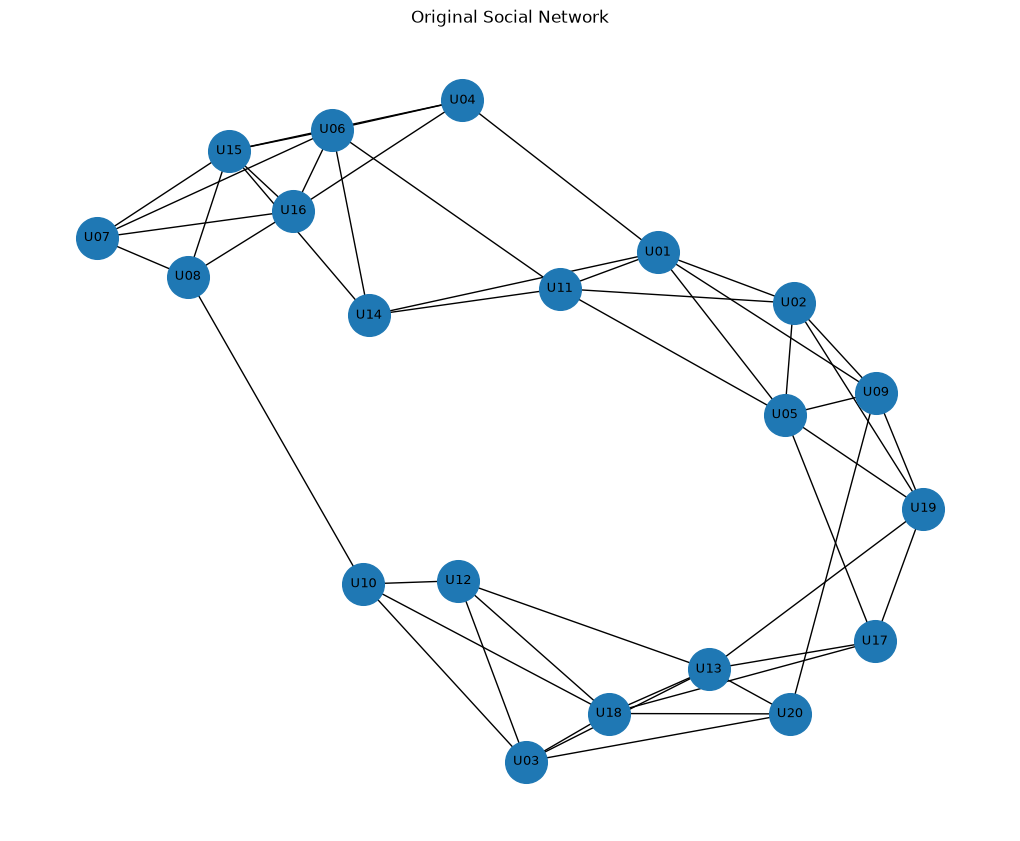

In [4]:
pos = nx.spring_layout(
    G,
    seed=42,
    k=0.8
)

plt.figure(figsize=(10, 8))

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=900,
    font_size=9
)

plt.title("Original Social Network")
plt.show()

**Pengamatan (sebelum menjalankan algoritma):**
- Secara visual terlihat adanya beberapa kelompok → Ya, terlihat ada sekitar **3 kelompok** utama.
- Terdapat node yang posisinya berada di antara beberapa kelompok, yaitu **U14** (yang terlihat menghubungkan beberapa cluster).

## G. Eksperimen 1 — Louvain

**Konsep:** Louvain mencari struktur community dengan meningkatkan Modularity. Secara sederhana: Move → Modularity ↑ → Merge

In [5]:
louvain = nx.community.louvain_communities(
    G,
    seed=42
)

print("Jumlah community:", len(louvain))

Jumlah community: 3


In [6]:
for i, community in enumerate(
    louvain,
    start=1
):
    print(
        f"Community {i}:",
        sorted(community)
    )

Community 1: ['U01', 'U02', 'U05', 'U09', 'U11', 'U19']
Community 2: ['U03', 'U10', 'U12', 'U13', 'U17', 'U18', 'U20']
Community 3: ['U04', 'U06', 'U07', 'U08', 'U14', 'U15', 'U16']


In [7]:
Q_louvain = nx.community.modularity(
    G,
    louvain
)

print("Modularity Louvain:", Q_louvain)

Modularity Louvain: 0.482923781757601


**Hasil:** $Q_{Louvain} = 0.4829$

## H. Eksperimen 2 — Label Propagation

**Konsep:** Setiap node mengikuti label yang dominan pada tetangganya. LABEL → NEIGHBOR → PROPAGATE

In [8]:
label_prop = list(
    nx.community.asyn_lpa_communities(
        G,
        seed=42
    )
)

print(
    "Jumlah community:",
    len(label_prop)
)

Jumlah community: 3


In [9]:
for i, community in enumerate(
    label_prop,
    start=1
):
    print(
        f"Community {i}:",
        sorted(community)
    )

Community 1: ['U01', 'U02', 'U05', 'U09', 'U11', 'U14', 'U19']
Community 2: ['U04', 'U06', 'U07', 'U08', 'U15', 'U16']
Community 3: ['U03', 'U10', 'U12', 'U13', 'U17', 'U18', 'U20']


In [10]:
Q_lp = nx.community.modularity(
    G,
    label_prop
)

print(
    "Modularity Label Propagation:",
    Q_lp
)

Modularity Label Propagation: 0.4804248229904206


**Hasil:** $Q_{LP} = 0.4804$

## I. Eksperimen 3 — Girvan-Newman

**Konsep:** Girvan-Newman mencari edge yang berperan sebagai jembatan menggunakan edge betweenness, kemudian edge tersebut secara bertahap dihilangkan: BRIDGE → REMOVE → SPLIT

In [11]:
from networkx.algorithms.community import girvan_newman

generator = girvan_newman(G)

girvan = None

for partition in generator:

    communities = list(partition)

    if len(communities) == 3:
        girvan = communities
        break

In [12]:
print(
    "Jumlah community:",
    len(girvan)
)

for i, community in enumerate(
    girvan,
    start=1
):
    print(
        f"Community {i}:",
        sorted(community)
    )

Jumlah community: 3
Community 1: ['U01', 'U02', 'U05', 'U09', 'U11', 'U19']
Community 2: ['U04', 'U06', 'U07', 'U08', 'U14', 'U15', 'U16']
Community 3: ['U03', 'U10', 'U12', 'U13', 'U17', 'U18', 'U20']


**Pertanyaan penting:**
Mengapa pada Girvan-Newman kita menentukan `len(communities) == 3` sedangkan pada Louvain tidak?

→ Karena Girvan-Newman bersifat **divisive (hierarchical)**: ia memulai dari satu graph utuh dan terus membagi dengan menghapus edge satu per satu. Proses ini menghasilkan urutan partisi dari 2, 3, 4, ... community. Kita harus **memilih sendiri** di titik mana kita berhenti. Louvain sebaliknya bersifat **bottom-up agglomerative** dan otomatis menemukan jumlah community optimal berdasarkan maksimasi modularity.

## J. Modularity Girvan-Newman

In [13]:
Q_gn = nx.community.modularity(
    G,
    girvan
)

print(
    "Modularity Girvan-Newman:",
    Q_gn
)

Modularity Girvan-Newman: 0.482923781757601


**Hasil:** $Q_{GN} = 0.4829$

## K. Visualisasi Community

In [14]:
def draw_communities(
    G,
    pos,
    communities,
    title
):

    community_map = {}

    for i, community in enumerate(
        communities
    ):

        for node in community:
            community_map[node] = i

    node_colors = [
        community_map[node]
        for node in G.nodes()
    ]

    plt.figure(figsize=(10, 8))

    nx.draw(
        G,
        pos,
        with_labels=True,
        node_color=node_colors,
        cmap=plt.cm.Set2,
        node_size=900,
        font_size=9
    )

    plt.title(title)

    plt.show()

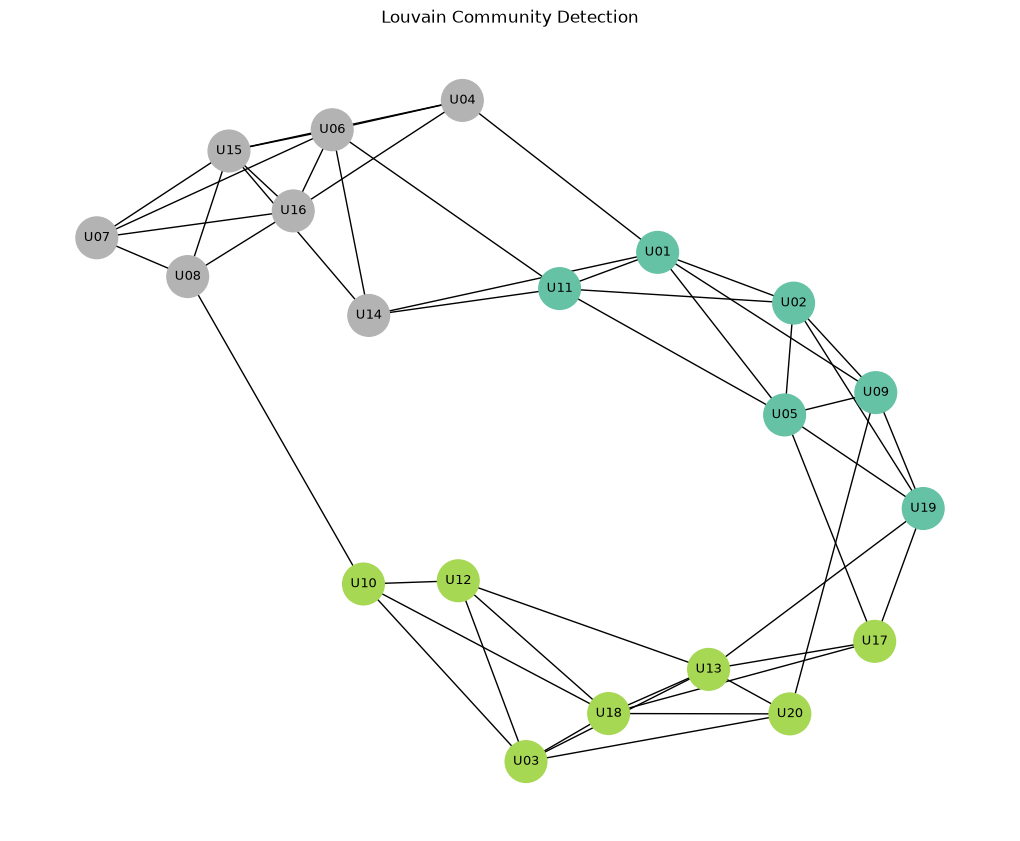

In [15]:
draw_communities(
    G,
    pos,
    louvain,
    "Louvain Community Detection"
)

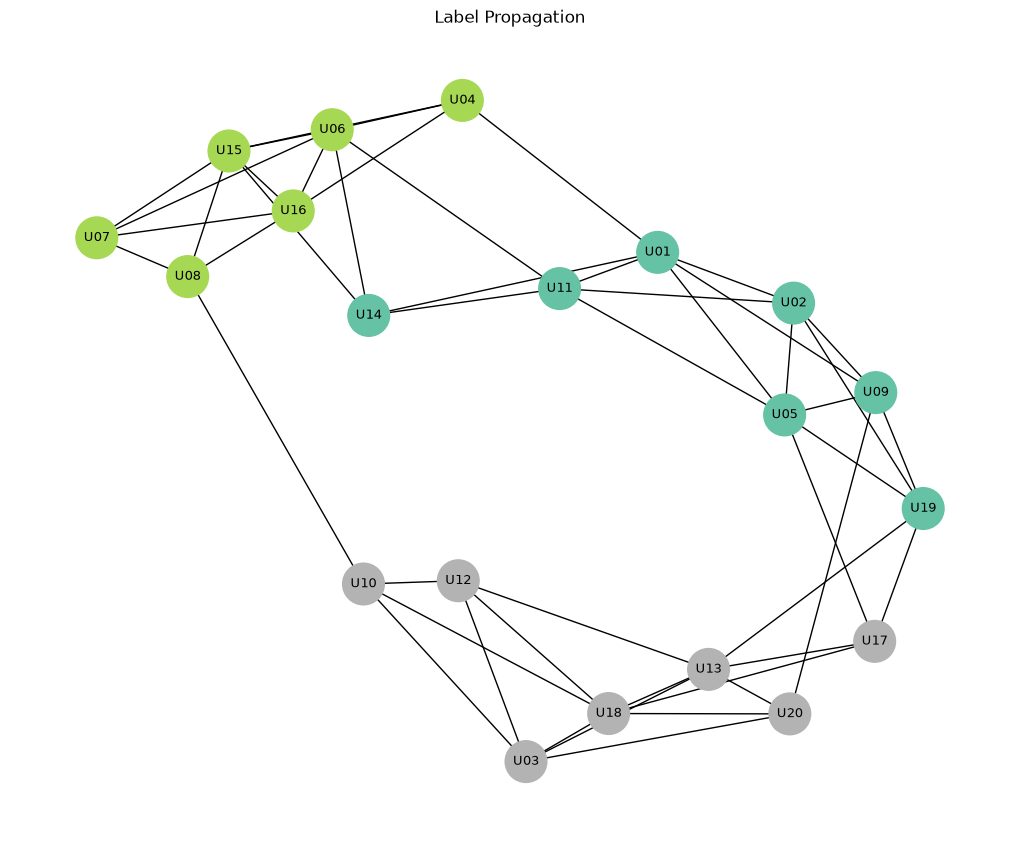

In [16]:
draw_communities(
    G,
    pos,
    label_prop,
    "Label Propagation"
)

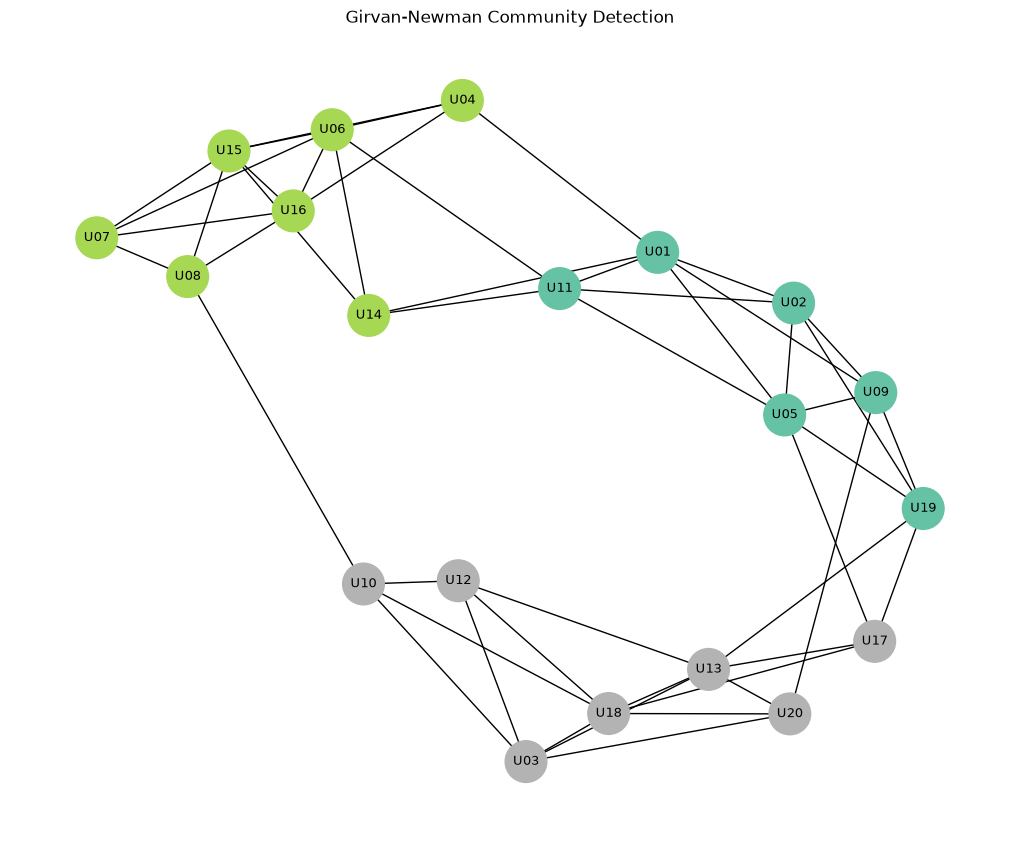

In [17]:
draw_communities(
    G,
    pos,
    girvan,
    "Girvan-Newman Community Detection"
)

## L. Membuat Tabel Keanggotaan

In [18]:
def get_membership(communities):

    membership = {}

    for i, community in enumerate(
        communities,
        start=1
    ):

        for node in community:

            membership[node] = (
                f"C{i}"
            )

    return membership

In [19]:
lou_dict = get_membership(louvain)
lp_dict  = get_membership(label_prop)
gn_dict  = get_membership(girvan)

nodes = sorted(G.nodes())

comparison = pd.DataFrame({
    "Node": nodes,

    "Louvain": [
        lou_dict[node]
        for node in nodes
    ],

    "Label Propagation": [
        lp_dict[node]
        for node in nodes
    ],

    "Girvan-Newman": [
        gn_dict[node]
        for node in nodes
    ]
})

print(comparison.to_string(index=False))

Node Louvain Label Propagation Girvan-Newman
 U01      C1                C1            C1
 U02      C1                C1            C1
 U03      C2                C3            C3
 U04      C3                C2            C2
 U05      C1                C1            C1
 U06      C3                C2            C2
 U07      C3                C2            C2
 U08      C3                C2            C2
 U09      C1                C1            C1
 U10      C2                C3            C3
 U11      C1                C1            C1
 U12      C2                C3            C3
 U13      C2                C3            C3
 U14      C3                C1            C2
 U15      C3                C2            C2
 U16      C3                C2            C2
 U17      C2                C3            C3
 U18      C2                C3            C3
 U19      C1                C1            C1
 U20      C2                C3            C3


In [20]:
evaluation = pd.DataFrame({

    "Method": [
        "Louvain",
        "Label Propagation",
        "Girvan-Newman"
    ],

    "Number of Communities": [
        len(louvain),
        len(label_prop),
        len(girvan)
    ],

    "Modularity": [
        Q_louvain,
        Q_lp,
        Q_gn
    ]
})

print(evaluation)

              Method  Number of Communities  Modularity
0            Louvain                      3    0.482924
1  Label Propagation                      3    0.480425
2      Girvan-Newman                      3    0.482924


In [21]:
community_rows = []

methods = {
    "Louvain": louvain,
    "Label Propagation": label_prop,
    "Girvan-Newman": girvan
}

for method, communities in methods.items():

    for i, community in enumerate(
        communities,
        start=1
    ):

        members = sorted(community)

        community_rows.append({
            "Method": method,
            "Community": f"C{i}",
            "Members": ", ".join(members),
            "Number of Members": len(members)
        })

community_table = pd.DataFrame(community_rows)

print(community_table.to_string(index=False))

           Method Community                           Members  Number of Members
          Louvain        C1      U01, U02, U05, U09, U11, U19                  6
          Louvain        C2 U03, U10, U12, U13, U17, U18, U20                  7
          Louvain        C3 U04, U06, U07, U08, U14, U15, U16                  7
Label Propagation        C1 U01, U02, U05, U09, U11, U14, U19                  7
Label Propagation        C2      U04, U06, U07, U08, U15, U16                  6
Label Propagation        C3 U03, U10, U12, U13, U17, U18, U20                  7
    Girvan-Newman        C1      U01, U02, U05, U09, U11, U19                  6
    Girvan-Newman        C2 U04, U06, U07, U08, U14, U15, U16                  7
    Girvan-Newman        C3 U03, U10, U12, U13, U17, U18, U20                  7


## T. Analisis Hasil

Sekarang bandingkan ketiga metode. Karena ketiga algoritma menggunakan prinsip yang berbeda, community yang ditemukan dapat sama atau berbeda. Ini merupakan salah satu tujuan utama eksperimen.

### Ringkasan Hasil

| Method | Number of Communities | Modularity |
|---|---|---|
| Louvain | 3 | 0.482924 |
| Label Propagation | 3 | 0.480425 |
| Girvan-Newman | 3 | 0.482924 |

## U. Tugas Analisis Mahasiswa

Lihat file `jawaban.md` untuk jawaban lengkap berdasarkan output program.

# Jawaban Tugas Analisis Mahasiswa
## Praktikum: Community Detection pada Social Network

> Semua jawaban berdasarkan output program yang telah dijalankan dengan dataset yang diberikan (NetworkX 3.7, seed=42).

---

## Output Program yang Dihasilkan

### Info Graph
- **Jumlah node:** 20
- **Jumlah edge:** 49

### Hasil Louvain
```
Jumlah community: 3
Community 1: ['U01', 'U02', 'U05', 'U09', 'U11', 'U19']
Community 2: ['U03', 'U10', 'U12', 'U13', 'U17', 'U18', 'U20']
Community 3: ['U04', 'U06', 'U07', 'U08', 'U14', 'U15', 'U16']
Modularity Louvain: 0.482923781757601
```

### Hasil Label Propagation
```
Jumlah community: 3
Community 1: ['U01', 'U02', 'U05', 'U09', 'U11', 'U14', 'U19']
Community 2: ['U04', 'U06', 'U07', 'U08', 'U15', 'U16']
Community 3: ['U03', 'U10', 'U12', 'U13', 'U17', 'U18', 'U20']
Modularity Label Propagation: 0.4804248229904206
```

### Hasil Girvan-Newman (3 community)
```
Jumlah community: 3
Community 1: ['U01', 'U02', 'U05', 'U09', 'U11', 'U19']
Community 2: ['U04', 'U06', 'U07', 'U08', 'U14', 'U15', 'U16']
Community 3: ['U03', 'U10', 'U12', 'U13', 'U17', 'U18', 'U20']
Modularity Girvan-Newman: 0.482923781757601
```

---

## Bagian E — Pertanyaan Dasar

**1. Berapa jumlah node?**

Jumlah node adalah **20 node** (U01 hingga U20).

**2. Berapa jumlah edge?**

Jumlah edge adalah **49 edge**.

**3. Mengapa graph yang digunakan merupakan `nx.Graph()` dan bukan `nx.DiGraph()`?**

Karena hubungan dalam social network ini bersifat **tidak berarah (undirected)**. Jika pengguna A terhubung dengan pengguna B, maka B juga terhubung dengan A — hubungannya bersifat timbal balik dan simetris. `nx.Graph()` merepresentasikan graph tak berarah, sedangkan `nx.DiGraph()` digunakan untuk graph berarah di mana edge memiliki arah tertentu (seperti follower di Twitter).

---

## Bagian F — Pengamatan Visual (Sebelum Algoritma)

**Apakah secara visual terlihat adanya beberapa kelompok?**

Ya, secara visual terlihat adanya beberapa cluster node yang saling berdekatan dan terhubung lebih rapat satu sama lain dibanding dengan node di luar cluster.

**Kira-kira berapa community yang terlihat?**

Terlihat sekitar **3 kelompok** utama yang cukup jelas dari visualisasi spring layout.

**Apakah terdapat node yang posisinya berada di antara beberapa kelompok?**

Ya. Node **U14** dan **U04** terlihat berada di posisi yang menjembatani beberapa kelompok karena memiliki koneksi ke lebih dari satu cluster.

---

## Bagian I — Pertanyaan Penting Girvan-Newman

**Mengapa pada Girvan-Newman kita menentukan `len(communities) == 3` sedangkan pada Louvain tidak? Diskusikan sifat hierarchical/divisive dari Girvan-Newman.**

Girvan-Newman adalah algoritma **divisive (top-down/hierarchical)**: ia memulai dari satu graph utuh dan secara bertahap membaginya menjadi sub-graph dengan cara menghapus edge yang memiliki nilai *edge betweenness* tertinggi (edge yang paling banyak dilalui jalur terpendek antar node — yaitu edge jembatan). Proses ini menghasilkan urutan partisi secara hierarkis:

```
1 community → 2 communities → 3 communities → 4 communities → ...
```

Karena algoritma tidak memiliki kriteria berhenti otomatis berdasarkan kualitas partisi, kita harus **secara eksplisit menentukan** di titik mana kita berhenti (dalam hal ini, saat jumlah community mencapai 3).

Louvain sebaliknya bersifat **agglomerative (bottom-up)**: setiap node dimulai sebagai community sendiri, lalu digabungkan berdasarkan peningkatan nilai modularity. Algoritma ini **otomatis berhenti** ketika modularity tidak bisa ditingkatkan lagi, sehingga jumlah community optimal ditemukan secara otomatis tanpa perlu ditentukan manual.

---

## Bagian U — Tugas Analisis Mahasiswa (10 Pertanyaan)

### 1. Berapa community yang dihasilkan Louvain?

Louvain menghasilkan **3 community**, yaitu:

| Community | Anggota | Jumlah |
|-----------|---------|--------|
| C1 | U01, U02, U05, U09, U11, U19 | 6 node |
| C2 | U03, U10, U12, U13, U17, U18, U20 | 7 node |
| C3 | U04, U06, U07, U08, U14, U15, U16 | 7 node |

---

### 2. Berapa community yang dihasilkan Label Propagation?

Label Propagation menghasilkan **3 community**, yaitu:

| Community | Anggota | Jumlah |
|-----------|---------|--------|
| C1 | U01, U02, U05, U09, U11, U14, U19 | 7 node |
| C2 | U04, U06, U07, U08, U15, U16 | 6 node |
| C3 | U03, U10, U12, U13, U17, U18, U20 | 7 node |

---

### 3. Bagaimana partition 3-community dari Girvan-Newman?

Partition 3-community dari Girvan-Newman menghasilkan:

| Community | Anggota | Jumlah |
|-----------|---------|--------|
| C1 | U01, U02, U05, U09, U11, U19 | 6 node |
| C2 | U04, U06, U07, U08, U14, U15, U16 | 7 node |
| C3 | U03, U10, U12, U13, U17, U18, U20 | 7 node |

Partisi ini diperoleh setelah Girvan-Newman menghapus edge-edge jembatan (bridge edges) secara bertahap hingga graph terbagi menjadi tepat 3 komponen terpisah. C1 berpusat pada koneksi rapat antara U01–U02–U05–U09, C2 pada cluster U06–U07–U08–U15–U16, dan C3 pada cluster U13–U18–U17–U20.

---

### 4. Apakah ketiga metode menghasilkan struktur yang sama?

**Secara substansial hampir sama, tetapi tidak identik.**

Ketiga metode sama-sama menemukan **3 community** dengan komposisi node yang sangat mirip. Perbedaan hanya terjadi pada **1 node**, yaitu **U14**:

| Node | Louvain | Label Propagation | Girvan-Newman |
|------|---------|-------------------|---------------|
| U14  | C3 (bersama U04, U06...) | C1 (bersama U01, U02...) | C2 (bersama U04, U06...) |

Selain U14, **19 node lainnya** ditempatkan dalam kelompok yang secara struktural sama oleh ketiga metode (meski nomor community berbeda karena labeling yang berbeda).

---

### 5. Node mana yang paling jelas berubah kelompok antar-metode?

**U14** adalah satu-satunya node yang berpindah kelompok antar-metode:

- **Louvain:** masuk C3 (bersama U04, U06, U07, U08, U15, U16)
- **Label Propagation:** masuk C1 (bersama U01, U02, U05, U09, U11, U19)
- **Girvan-Newman:** masuk C2 (bersama U04, U06, U07, U08, U15, U16)

Louvain dan Girvan-Newman sepakat menempatkan U14 di cluster yang sama (meskipun berbeda nomor label), sedangkan Label Propagation memasukkan U14 ke cluster yang berbeda.

---

### 6. Perhatikan struktur koneksi node tersebut. Mengapa membership-nya mungkin ambigu?

**U14** memiliki koneksi ke **dua cluster berbeda** secara hampir seimbang:

- **Ke cluster U01-U02-U05-U09-U11-U19:** terhubung ke U01 (edge `U14–U01`) dan U11 (edge `U14–U11`) → 2 koneksi
- **Ke cluster U04-U06-U07-U08-U15-U16:** terhubung ke U06 (edge `U14–U06`) dan U15 (edge `U14–U15`) → 2 koneksi

Karena jumlah koneksi U14 ke masing-masing cluster **sama banyak (2 ke masing-masing sisi)**, U14 adalah **node jembatan (bridge node)** yang tidak memiliki keanggotaan yang kuat ke salah satu cluster. Algoritma yang berbeda dengan cara evaluasi yang berbeda pun dapat menempatkan U14 di salah satu cluster tergantung kriteria yang digunakan, sehingga membership-nya menjadi ambigu.

---

### 7. Metode mana yang menghasilkan modularity tertinggi?

Berdasarkan output program:

| Method | Modularity |
|--------|-----------|
| Louvain | **0.482924** |
| Label Propagation | 0.480425 |
| Girvan-Newman | **0.482924** |

**Louvain dan Girvan-Newman** keduanya menghasilkan modularity tertinggi yang sama persis: **Q = 0.4829**. Label Propagation sedikit lebih rendah (0.4804). Louvain dan Girvan-Newman menghasilkan nilai modularity identik karena keduanya menghasilkan partisi yang strukturnya sama persis (hanya berbeda penamaan label).

---

### 8. Mengapa hasil Louvain dan Girvan-Newman bisa sama meskipun mekanismenya berbeda?

Meskipun Louvain (bottom-up, agglomerative, memaksimalkan modularity) dan Girvan-Newman (top-down, divisive, menghapus bridge edges) menggunakan mekanisme yang berlawanan, keduanya menemukan partisi yang sama karena:

1. **Struktur graph yang kuat:** Ketika ada 3 cluster yang terdefinisi jelas dengan densitas koneksi internal jauh lebih tinggi daripada koneksi antar-cluster, kedua algoritma cenderung menemukan pembagian yang sama.

2. **Konvergensi ke optimum yang sama:** Louvain secara eksplisit memaksimalkan modularity. Girvan-Newman secara implisit juga menemukan titik pemisahan yang optimal karena edge yang dihapus pertama kali (bridge edges dengan betweenness tertinggi) adalah tepat edge yang menghubungkan antar-community — sehingga hasilnya konvergen ke partisi yang sama.

3. **Bukti numerik:** Kedua metode menghasilkan Q = 0.4829 yang identik, mengkonfirmasi bahwa keduanya menemukan pembagian community yang secara kuantitatif optimal.

---

### 9. Mengapa Label Propagation dapat menghasilkan pembagian berbeda?

Label Propagation menghasilkan pembagian berbeda (khususnya untuk U14) karena:

1. **Mekanisme propagasi label lokal:** Algoritma ini memperbarui label setiap node berdasarkan label mayoritas tetangganya secara iteratif. Prosesnya bersifat **asynchronous** — urutan pemrosesan node antar iterasi bersifat semi-acak. Meskipun `seed=42` dipasang untuk reproducibility, arah propagasi label tetap sensitif terhadap urutan pemrosesan.

2. **Tidak secara eksplisit mengoptimasi modularity:** Label Propagation tidak menghitung modularity — ia hanya mengikuti dominasi label lokal. Karena U14 memiliki 2 tetangga di setiap cluster, jika label dari cluster U01 lebih dulu menyebar ke U14 sebelum label dari cluster U06 mencapainya, maka U14 akan tertarik ke cluster U01.

3. **Trade-off kecepatan vs. akurasi:** Label Propagation dirancang untuk sangat cepat (O(m) per iterasi), sehingga mengorbankan sedikit akurasi dibanding metode yang secara eksplisit mengoptimasi kualitas community. Hasilnya modularity sedikit lebih rendah (0.4804 vs 0.4829).

---

### 10. Apakah modularity yang lebih tinggi otomatis berarti metode tersebut selalu terbaik untuk semua aplikasi? Jelaskan.

**Tidak.** Modularity yang lebih tinggi tidak selalu berarti metode tersebut terbaik untuk semua aplikasi. Beberapa alasan penting:

1. **Resolution limit (keterbatasan resolusi):** Modularity memiliki keterbatasan bawaan dalam mendeteksi community yang sangat kecil di dalam graph yang besar. Community kecil tapi nyata dan bermakna bisa terlewatkan oleh algoritma yang hanya mengoptimasi modularity global.

2. **Kesesuaian dengan konteks aplikasi:**
   - Dalam **deteksi fraud/keamanan siber**, akurasi pengelompokan lebih penting dari modularity.
   - Dalam **sistem rekomendasi produk**, community yang lebih granular (lebih banyak, lebih kecil) bisa lebih berguna meskipun modularitynya lebih rendah.
   - Dalam **analisis jaringan besar** (jutaan node), Label Propagation yang sedikit lebih rendah modularitynya tetapi jauh lebih cepat bisa menjadi pilihan terbaik secara praktis.

3. **Stabilitas dan reproducibility:** Metode dengan modularity tinggi namun sensitif terhadap kondisi awal (seperti Louvain) bisa menghasilkan partisi berbeda di setiap run jika seed tidak dikontrol.

4. **Ground truth:** Jika terdapat label community yang sebenarnya (ground truth), metode terbaik adalah yang paling akurat memprediksi label tersebut — bukan yang memiliki modularity tertinggi.

**Kesimpulan:** Modularity adalah metrik evaluasi yang berguna sebagai indikator kualitas community, tetapi pemilihan metode terbaik harus mempertimbangkan tujuan aplikasi, ukuran graph, ketersediaan ground truth, kebutuhan kecepatan komputasi, dan kemampuan interpretasi hasil.

---

## Tabel Keanggotaan Node (dari Output Program)

| Node | Louvain | Label Propagation | Girvan-Newman |
|------|---------|-------------------|---------------|
| U01  | C1      | C1                | C1            |
| U02  | C1      | C1                | C1            |
| U03  | C2      | C3                | C3            |
| U04  | C3      | C2                | C2            |
| U05  | C1      | C1                | C1            |
| U06  | C3      | C2                | C2            |
| U07  | C3      | C2                | C2            |
| U08  | C3      | C2                | C2            |
| U09  | C1      | C1                | C1            |
| U10  | C2      | C3                | C3            |
| U11  | C1      | C1                | C1            |
| U12  | C2      | C3                | C3            |
| U13  | C2      | C3                | C3            |
| **U14**  | **C3**  | **C1**            | **C2**        |
| U15  | C3      | C2                | C2            |
| U16  | C3      | C2                | C2            |
| U17  | C2      | C3                | C3            |
| U18  | C2      | C3                | C3            |
| U19  | C1      | C1                | C1            |
| U20  | C2      | C3                | C3            |

> **U14** (ditandai tebal) adalah satu-satunya node yang berbeda kelompok antar metode.

## Tabel Evaluasi Akhir

| Method            | Number of Communities | Modularity  |
|-------------------|-----------------------|-------------|
| Louvain           | 3                     | **0.482924** |
| Label Propagation | 3                     | 0.480425    |
| Girvan-Newman     | 3                     | **0.482924** |
